In [1]:
%pip install chefboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: C:\Program Files\Python313\python.exe -m pip install --upgrade pip


# Experiment 08: C4.5 Decision Tree Classification

## Aim
To implement a C4.5 decision tree classifier and evaluate its classification performance.

## Dataset and source
- **Dataset:** Breast Cancer Wisconsin Diagnostic
- **Source:** Built into scikit-learn (`load_breast_cancer`)
- **Size:** 569 samples, 30 numeric features
- **Classes:** malignant and benign
- **Kaggle download:** Not required

## Theory
C4.5 is a decision tree algorithm developed by Ross Quinlan. It extends ID3 by supporting continuous-valued attributes, handling missing values, and using **gain ratio** to select splits. It can also prune the tree to reduce overfitting.

Information gain measures the reduction in entropy after a split:

\[
Gain(S,A)=Entropy(S)-\sum_{v\in Values(A)}\frac{|S_v|}{|S|}Entropy(S_v)
\]

Gain ratio normalizes information gain by the split information:

\[
GainRatio(S,A)=\frac{Gain(S,A)}{SplitInfo(S,A)}
\]

where

\[
SplitInfo(S,A)=-\sum_{v\in Values(A)}\frac{|S_v|}{|S|}\log_2\frac{|S_v|}{|S|}
\]

**Implementation note:** `sklearn.tree.DecisionTreeClassifier(criterion="entropy")` uses information gain, not gain ratio, so it should not be described as a true C4.5 implementation. This notebook uses the third-party `chefboost` package with `algorithm="C4.5"`.

## Algorithm
1. Load the built-in Breast Cancer Wisconsin dataset.
2. Combine features and class labels, keeping the target column last.
3. Split the records into training and testing sets.
4. Train Chefboost using the C4.5 algorithm.
5. Predict classes for the test records.
6. Evaluate accuracy, precision, recall, F1-score, and confusion matrix.
7. Display the confusion matrix and example predictions.

## Installation
Run this in a Jupyter cell if Chefboost is not installed:

```python
%pip install chefboost
```

Then restart the kernel and run the notebook. Use the same Python environment for installation and execution.


## Program


Dataset: Breast Cancer Wisconsin Diagnostic
Dataset source: scikit-learn built-in dataset
Number of rows: 569
Number of features: 30
Class labels: {0: np.str_('malignant'), 1: np.str_('benign')}

Training samples: 455
Testing samples: 114
26-10-28 07:14:13 - C4.5 tree is going to be built...
26-10-28 07:14:30 - -------------------------
26-10-28 07:14:30 - finished in 17.08634328842163 seconds
26-10-28 07:14:30 - -------------------------
26-10-28 07:14:30 - Evaluate train set
26-10-28 07:14:30 - -------------------------
26-10-28 07:14:30 - Accuracy: 96.26373626373626% on 455 instances
26-10-28 07:14:30 - Labels: ['benign' 'malignant']
26-10-28 07:14:30 - Confusion matrix: [[281, 13], [4, 157]]
26-10-28 07:14:30 - Precision: 95.5782%, Recall: 98.5965%, F1: 97.0639%

Algorithm: C4.5 Decision Tree (gain ratio)
Accuracy: 0.9386 (93.86%)

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.88      0.91        42
      benign       0

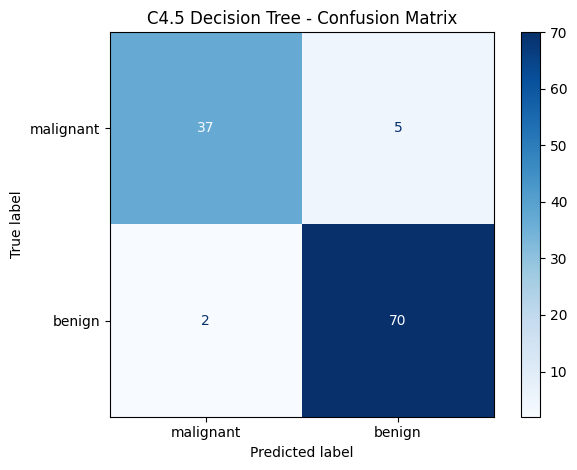


Sample predictions:
Sample 1: Predicted = malignant, Actual = malignant
Sample 2: Predicted = benign, Actual = benign
Sample 3: Predicted = benign, Actual = malignant
Sample 4: Predicted = malignant, Actual = benign
Sample 5: Predicted = malignant, Actual = malignant

Note: Chefboost builds its own tree files when training. If the package/API version differs, check the Chefboost documentation or install it in the same environment as this notebook.


In [2]:
"""
Experiment 08: C4.5 Decision Tree Classification
Dataset: Breast Cancer Wisconsin Diagnostic (built into scikit-learn)

Important implementation note:
C4.5 uses gain ratio for split selection and handles continuous features.
scikit-learn's DecisionTreeClassifier(criterion="entropy") uses information
gain, not gain ratio, so it is NOT a true C4.5 implementation.
This experiment uses the open-source `chefboost` package with algorithm="C4.5".
"""

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

# C4.5 implementation package
try:
    from chefboost import Chefboost as chef
except ImportError as exc:
    raise SystemExit(
        "Missing package 'chefboost'. Install it in your Jupyter environment "
        "with: %pip install chefboost\n"
        "Then restart the kernel and run this program again."
    ) from exc

# 1. Load dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target
target_names = data.target_names

print("Dataset: Breast Cancer Wisconsin Diagnostic")
print("Dataset source: scikit-learn built-in dataset")
print(f"Number of rows: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print("Class labels:", dict(enumerate(target_names)))

# Chefboost expects the target column to be the final column.
df = X.copy()
df["Decision"] = y.map({0: "malignant", 1: "benign"})

# 2. Split data; stratify preserves class proportions.
train_df, test_df = train_test_split(
    df, test_size=0.20, random_state=42, stratify=y
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("\nTraining samples:", len(train_df))
print("Testing samples:", len(test_df))

# 3. Train C4.5 model using gain ratio.
config = {
    "algorithm": "C4.5",
    "enableParallelism": False
}
model = chef.fit(train_df, config=config, target_label="Decision")

# 4. Predict test samples.
# Chefboost's predict accepts a list of feature values in the same order as X.
feature_names = list(X.columns)
y_true = test_df["Decision"].tolist()
y_pred = []

for _, row in test_df[feature_names].iterrows():
    prediction = chef.predict(model, row.tolist())
    # Normalize common prediction return formats.
    if isinstance(prediction, (list, tuple)):
        prediction = prediction[0]
    if hasattr(prediction, "item"):
        prediction = prediction.item()
    y_pred.append(str(prediction).strip())

# Normalize labels to avoid casing/whitespace differences.
y_true_norm = [str(v).strip().lower() for v in y_true]
y_pred_norm = [str(v).strip().lower() for v in y_pred]

# 5. Evaluate
accuracy = accuracy_score(y_true_norm, y_pred_norm)
labels = ["malignant", "benign"]

print("\nAlgorithm: C4.5 Decision Tree (gain ratio)")
print(f"Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")
print("\nClassification Report:")
print(classification_report(
    y_true_norm, y_pred_norm, labels=labels,
    target_names=labels, zero_division=0
))
cm = confusion_matrix(y_true_norm, y_pred_norm, labels=labels)
print("Confusion Matrix (malignant, benign):")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(cmap="Blues", values_format="d")
plt.title("C4.5 Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.show()

# 6. Show a few sample predictions
print("\nSample predictions:")
for i in range(min(5, len(test_df))):
    print(
        f"Sample {i + 1}: Predicted = {y_pred[i]}, "
        f"Actual = {y_true_norm[i]}"
    )

print(
    "\nNote: Chefboost builds its own tree files when training. "
    "If the package/API version differs, check the Chefboost documentation "
    "or install it in the same environment as this notebook."
)


## Expected output
The program prints dataset dimensions, train/test sizes, classification metrics, a confusion matrix, and several sample predictions. It also plots the confusion matrix.

The exact metrics depend on the Chefboost version and the learned tree. The first training run may create a generated tree/model folder in the working directory.

## Result
The C4.5 decision tree was trained on the Breast Cancer Wisconsin dataset and evaluated on held-out test data using classification metrics.

## Viva-voce questions and answers

**1. What is C4.5?**  
C4.5 is a decision tree algorithm developed by Ross Quinlan for classification.

**2. Which criterion does C4.5 use to select splits?**  
Gain ratio, which adjusts information gain using split information.

**3. What is the difference between ID3 and C4.5?**  
ID3 primarily uses information gain and is designed for categorical attributes; C4.5 adds gain ratio, handles continuous attributes and missing values, and includes pruning.

**4. What is entropy?**  
Entropy measures the uncertainty or impurity of a class distribution.

**5. What is information gain?**  
Information gain is the reduction in entropy resulting from splitting data on an attribute.

**6. Why use gain ratio instead of information gain alone?**  
Information gain can favor attributes with many distinct values. Gain ratio normalizes it by split information to reduce this bias.

**7. What is pruning?**  
Pruning removes branches that are unlikely to improve generalization, helping reduce overfitting.

**8. Can C4.5 handle continuous features?**  
Yes. It can choose thresholds to split continuous-valued attributes.

**9. Is scikit-learn's `criterion="entropy"` exactly C4.5?**  
No. It uses entropy/information gain, but does not use C4.5's gain-ratio split criterion.

**10. What is a confusion matrix?**  
A table comparing actual and predicted classes, showing correct and incorrect predictions for each class.
